In [1]:
import pandas as pd
import re

def parse_theorem_file(file_path):
    with open(file_path, 'r') as f:
        content = f.read()
    
    # Split by THEOREM to get individual theorem blocks
    theorem_blocks = re.split(r'\n(?=THEOREM:)', content.strip())
    
    theorems_data = []
    
    for block in theorem_blocks:
        if not block.strip():
            continue
            
        lines = block.strip().split('\n')
        
        # Initialize variables for this theorem
        theorem_name = None
        goal = None
        expansions = None
        goals = []
        steps = []
        
        for line in lines:
            line = line.strip()
            
            if line.startswith('THEOREM:'):
                theorem_name = line.replace('THEOREM:', '').strip()
            elif line.startswith('GOAL:') and goal is None:
                # This is the main goal (first GOAL line)
                goal = line.replace('GOAL:', '').strip()
            elif line.startswith('EXPANSIONS:'):
                expansions = int(line.replace('EXPANSIONS:', '').strip())
            elif line.startswith('GOAL:') and goal is not None:
                # These are sub-goals
                goals.append(line.replace('GOAL:', '').strip())
            elif line.startswith('STEP:'):
                steps.append(line.replace('STEP:', '').strip())
        
        theorems_data.append({
            'theorem_name': theorem_name,
            'expansions': expansions,
            'goal': goal,
            'sub_goals': goals,
            'steps': steps
        })
    
    return pd.DataFrame(theorems_data)



In [2]:
# Parse the file
baseline_df = parse_theorem_file('./baseline/longest_theorems_proved.txt')
residual_df = parse_theorem_file('./residual/baseline/NEq3-cap3/longest_theorems_proved.txt')
baseline_mod_df = parse_theorem_file('./modular/longest_theorems_proved.txt')
residual_mod_df = parse_theorem_file('./residual/modular/NEq3-batched/longest_theorems_proved.txt')

# Display the dataframe
dfs = {
    'Baseline Modular': baseline_mod_df,
    'Baseline': baseline_df,
    'Residual': residual_df,
    'Residual Modular': residual_mod_df,
}

In [3]:
from itertools import combinations

names = {k: set(df['theorem_name']) for k, df in dfs.items()}

# Per-file counts
for k, s in names.items():
    print(f"{k}: {len(s)} theorems")

# Pairwise overlaps
print("\nPairwise overlaps:")
for a, b in combinations(names, 2):
    print(f"  {a} ∩ {b}: {len(names[a] & names[b])}")

# Common to all
common_all = set.intersection(*names.values())
print(f"\nCommon to all {len(names)}: {len(common_all)}")

# Union
union_all = set.union(*names.values())
print(f"Union: {len(union_all)}")

Baseline Modular: 129 theorems
Baseline: 130 theorems
Residual: 131 theorems
Residual Modular: 121 theorems

Pairwise overlaps:
  Baseline Modular ∩ Baseline: 85
  Baseline Modular ∩ Residual: 84
  Baseline Modular ∩ Residual Modular: 85
  Baseline ∩ Residual: 96
  Baseline ∩ Residual Modular: 81
  Residual ∩ Residual Modular: 86

Common to all 4: 57
Union: 205


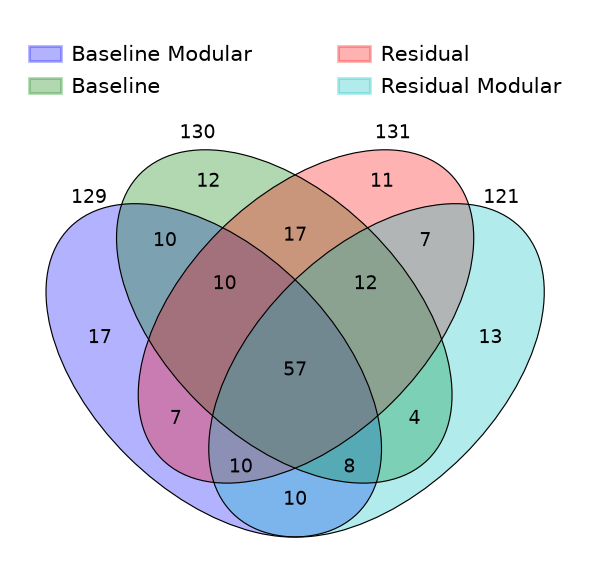

In [4]:
from venny4py.venny4py import venny4py

# names is your existing {k: set(...)} dict
venny4py(sets=names, out='.', ext='png', dpi=150)

In [5]:
all_names = sorted(union_all)
membership = pd.DataFrame(
    {k: [n in names[k] for n in all_names] for k in names},
    index=all_names
)
print(membership)

           Baseline Modular  Baseline  Residual  Residual Modular
0inp0                 False     False      True              True
0nep0                 False      True     False             False
19.12                  True      True      True              True
19.28v                 True      True      True              True
19.33                  True      True      True              True
...                     ...       ...       ...               ...
unisn2                False      True     False             False
vtoclegft             False     False      True              True
vuniex                 True      True      True              True
xpex                  False      True     False              True
xpexr2                 True      True      True             False

[205 rows x 4 columns]


In [6]:
collapsed = {
    k: df.groupby('theorem_name', as_index=False)['expansions'].first().set_index('theorem_name')
    for k, df in dfs.items()
}

expansions = pd.concat(
    {k: c['expansions'] for k, c in collapsed.items()},
    axis=1
)
# Only theorems present in ALL files
expansions_common = expansions.loc[list(common_all)]
print(expansions_common)

              Baseline Modular  Baseline  Residual  Residual Modular
theorem_name                                                        
ax10w                      1.0       1.0       1.0               1.0
an42                       4.0       4.0      14.0              11.0
sbid2v                     3.0       3.0       3.0               3.0
ax9v2                      1.0       1.0       1.0               1.0
elequ1                     1.0       1.0       1.0               1.0
simp32l                    2.0       3.0       2.0               2.0
fnexALT                    1.0       1.0       1.0               1.0
simp2r2                    2.0       2.0       6.0               3.0
nic-luk2                   1.0       1.0       1.0               1.0
ficardid                   3.0       3.0       3.0               3.0
dmfex                     14.0       4.0       4.0              30.0
simp2r3                    2.0       2.0       3.0               2.0
rabeqf                     1.0    

In [7]:
winners = expansions_common.idxmin(axis=1)
# print(winners)

print(winners.value_counts())

Baseline Modular    38
Baseline            12
Residual Modular     4
Residual             3
Name: count, dtype: int64
